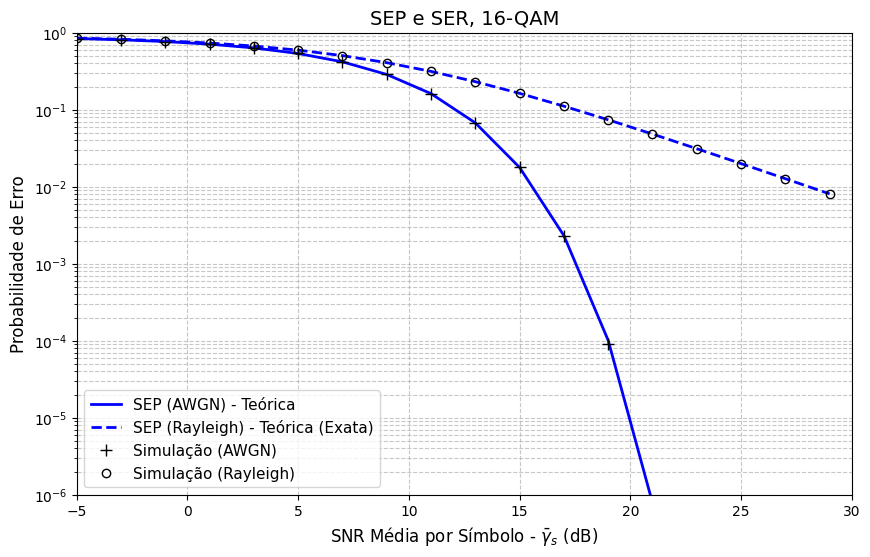

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erfc

def gerar_constelacao(M):
    L = int(np.sqrt(M))
    energia_media_da_constelacao = 1
    d = np.sqrt((3 * energia_media_da_constelacao) / (2 * (M - 1)))

    eixo = d * np.arange(-(L-1), L, 2)
    I, Q = np.meshgrid(eixo, eixo)

    C = (I + 1j * Q).flatten()
    return C

def Q(x):
    return 0.5 * erfc(x / np.sqrt(2))

def calcular_sep_teorica_awgn(M, gamma_s):
    termo_M = 1 - (1 / np.sqrt(M))
    arg_Q = np.sqrt((3 / (M - 1)) * gamma_s)
    q_val = Q(arg_Q)
    sep = 4 * termo_M * q_val - 4 * (termo_M**2) * (q_val**2)
    return sep

def calcular_sep_teorica_rayleigh(M, gamma_s_media):
    termo_M = (np.sqrt(M) - 1) / np.sqrt(M)
    C_M = np.sqrt((1.5 * gamma_s_media) / (M - 1 + 1.5 * gamma_s_media))

    termo1 = 2 * termo_M * (1 - C_M)
    termo2 = (termo_M**2) * (1 - (4 / np.pi) * C_M * np.arctan(1 / C_M))
    return termo1 - termo2

N_t = 10**6
M = 16
snr_db_vetor = np.arange(-5, 31, 2)

C = gerar_constelacao(M)
indices_tx = np.random.randint(0, M, size=N_t)
S_t = C[indices_tx]

ser_simulada_awgn = []
sep_teorica_awgn = []

ser_simulada_rayleigh = []
sep_teorica_rayleigh = []

for snr_db in snr_db_vetor:
    gamma_s_media = 10**(snr_db / 10)
    sigma_n = np.sqrt(1 / (2 * gamma_s_media))
    n = np.random.normal(0, sigma_n, size=N_t) + 1j * np.random.normal(0, sigma_n, size=N_t)

    r_awgn = S_t + n

    dist_awgn = np.abs(r_awgn[:, None] - C[None, :]) ** 2
    simbolos_decodificados_awgn = C[np.argmin(dist_awgn, axis=1)]

    N_erros_awgn = np.sum(S_t != simbolos_decodificados_awgn)
    ser_simulada_awgn.append(N_erros_awgn / N_t)
    sep_teorica_awgn.append(calcular_sep_teorica_awgn(M, gamma_s_media))

    x_ray = np.random.normal(0, np.sqrt(1/2), size=N_t)
    y_ray = np.random.normal(0, np.sqrt(1/2), size=N_t)
    beta = np.sqrt(x_ray**2 + y_ray**2)
    r_rayleigh = (beta * S_t) + n

    dist_rayleigh = np.abs(r_rayleigh[:, None] - (beta[:, None] * C[None, :])) ** 2
    simbolos_decodificados_rayleigh = C[np.argmin(dist_rayleigh, axis=1)]


    N_erros_rayleigh = np.sum(S_t != simbolos_decodificados_rayleigh)
    ser_simulada_rayleigh.append(N_erros_rayleigh / N_t)
    sep_teorica_rayleigh.append(calcular_sep_teorica_rayleigh(M, gamma_s_media))

plt.figure(figsize=(10, 6))
plt.semilogy(snr_db_vetor, sep_teorica_awgn, 'b-', linewidth=2, label='SEP (AWGN) - Teórica')
plt.semilogy(snr_db_vetor, sep_teorica_rayleigh, 'b--', linewidth=2, label='SEP (Rayleigh) - Teórica (Exata)')
plt.semilogy(snr_db_vetor, ser_simulada_awgn, 'k+', markersize=8, label='Simulação (AWGN)')
plt.semilogy(snr_db_vetor, ser_simulada_rayleigh, 'ko', markersize=6, markerfacecolor='none', label='Simulação (Rayleigh)')
plt.xlabel(r'SNR Média por Símbolo - $\bar{\gamma}_s$ (dB)', fontsize=12)
plt.ylabel('Probabilidade de Erro', fontsize=12)
plt.title('SEP e SER, 16-QAM', fontsize=14)
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.ylim(1e-6, 1)
plt.xlim(-5, 30)
plt.legend(loc='lower left', fontsize=11)
plt.show()